## **Closing the Urban–Rural Electrification Gap in Sub-Saharan Africa**
**SDG 7 (Affordable and Clean Energy), sub-target 7.1: universal access to electricity**


1. Business Understanding
2. Data Understanding (descriptive stats, EDA, missing-data investigation)
3. Data Preparation
4. Modelling (assumption tests, then four models)
5. Evaluation (R² and MSE, model comparison)
6. Deployment (best model as a pickle file + Power BI dashboard; Streamlit app as an extra)



## 1. Business Understanding

**SDG and target.** SDG 7, sub-target 7.1, indicator 7.1.1: the proportion of the population with access to electricity.

**The problem.** National "% electrified" figures hide a sharp urban–rural split. Roughly 82% of urban Sub-Saharan Africans had power in 2023, versus about a third of rural residents. Rural population growth is outpacing new rural connections, so the absolute number of people without power has stayed above 500 million for two decades.

     

**Business question.** *Which country-level economic and demographic factors are associated with the size of the urban–rural electrification gap, and how well can we predict it?*

**Why it matters (real-world use).** Funders and governments (e.g. Mission 300) must decide where to direct rural electrification money (grid extension, mini-grids, off-grid solar). A model that shows which factors move the gap helps prioritise countries and justify funding.

**Success criteria.**
- Descriptive picture of the gap across countries and over time.
- A linear regression of the gap on country-level predictors, evaluated on **unseen countries** with R² and MSE.
- A dashboard that lets a non-technical user explore the findings.

**Target variable:** `urban_rural_gap` = urban access % − rural access % (percentage points).
**Candidate predictors:** GDP per capita (log), urban population share, population growth, renewable share of final energy.

**Data sources :** `EG.ELC.ACCS.ZS` / `.UR.ZS` / `.RU.ZS`, `NY.GDP.PCAP.CD`, `SP.URB.TOTL.IN.ZS`, `SP.POP.GROW`, `SP.POP.TOTL`, `EG.FEC.RNEW.ZS`.

# Load The Libraries Used In THE Notebook

In [32]:
# 1. Files and system tools 
import glob, os, pickle, warnings   # glob/os: find files and folders; pickle: save the best model; warnings: control warning messages
from pathlib import Path            # Path: modern way to work with folder and file paths
import sklearn                      # scikit-learn itself (we store its version inside the saved model)

# 2. Data handling and charts
import numpy as np                  # numbers and maths (arrays, log, sqrt)
import pandas as pd                 # tables of data (DataFrames): load, clean...
import matplotlib.pyplot as plt     # basic charts
import seaborn as sns               # nicer statistical charts (heatmaps, themes)

# 3. Statistics: hypothesis tests and regression diagnostics
import scipy.stats as st            # chi-square, Mann-Whitney and Shapiro-Wilk tests
import statsmodels.api as sm        # regression with full statistics (coefficients, p-values, robust errors)
from statsmodels.stats.diagnostic import het_breuschpagan, linear_rainbow   # tests for constant variance and linearity
from statsmodels.stats.stattools import durbin_watson                       # test for independence of errors
from statsmodels.stats.outliers_influence import variance_inflation_factor  # VIF: checks multicollinearity

# --- 4. Splitting data and cross-validation (always keeping countries together) ---
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_val_score
# GroupShuffleSplit: train/test split by country
# GroupKFold: cross-validation that keeps each country in one fold
# GridSearchCV: tries different model settings to find the best
# cross_val_score: scores a model across the folds

# --- 5. Preparing data and building models ---
from sklearn.preprocessing import StandardScaler     # puts predictors on the same scale
from sklearn.pipeline import make_pipeline           # chains steps (scale, then model) so test data never leaks into training
from sklearn.linear_model import LinearRegression, RidgeCV, Ridge   # Linear Regression, and Ridge (RidgeCV picks its own penalty)
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor  # the two tree-based models
from sklearn.inspection import permutation_importance  # shows which predictors matter most
from sklearn.base import clone                       # makes a fresh, unfitted copy of a model
from sklearn.metrics import r2_score, mean_squared_error  # the two evaluation metrics: R-squared and MSE

# --- 6. Settings ---
warnings.filterwarnings("ignore", category=FutureWarning)  # hide harmless "future version" warnings so output stays clean
pd.set_option("display.max_columns", 20)                   # show up to 20 columns when printing a table
sns.set_theme(style="whitegrid")                           # consistent chart style with light grid lines
RANDOM_STATE = 42                                          # fixed random seed so results are the same every time you run it

from pathlib import Path  # needed for Path.cwd() and all the path operations below


def locate_data_dir(marker="API_EG.ELC.ACCS.ZS_*.csv"):
    # Finds the folder holding the World Bank CSVs, whatever folder the notebook runs from

    # Absolute path of the folder the notebook is currently running in
    # (resolve() cleans up any ".." parts or symlinks)
    start = Path.cwd().resolve()

    # Build the list of folders to search: the current folder plus its parents,
    # keeping only the first 4 so we don't climb all the way to the filesystem root
    for base in [start, *start.parents][:4]:

        # In each folder, check the folder itself and a "data" subfolder inside it
        for sub in [base, base / "data"]:

            # Skip candidates that don't exist (e.g. no "data" folder here).
            # Otherwise search recursively (rglob) for any file matching the pattern;
            # any() stops at the first match, so it doesn't scan everything
            if sub.is_dir() and any(sub.rglob(marker)):
                # Found it: return the folder path as a string
                return str(sub)

    # Nothing matched in any candidate folder: stop with a clear error message
    raise FileNotFoundError(f"Could not find {marker} near {start}")


# Run the search once and store the folder path for use in the rest of the notebook
DATA_DIR = locate_data_dir()

# Show where the notebook is running and which data folder was picked (useful for debugging paths)
print("Working folder:", Path.cwd())
print("Using data in :", DATA_DIR)

Working folder: c:\Users\user\Desktop\Analysis101\SDG7_Capstone
Using data in : C:\Users\user\Desktop\Analysis101


## 2. Data Understanding

### 2.1 Loading
World Bank CSVs start with 4 metadata rows, hence `skiprows=4`. Each file is wide (one column per year), so we *melt* it to long format (one row per country-year).
`find_wb_file` locates a file by its indicator code, so the notebook does not depend on exact folder names.

In [2]:
def find_wb_file(code):
    hits = glob.glob(os.path.join(DATA_DIR, "**", f"API_{code}_*.csv"), recursive=True)
    if not hits:
        raise FileNotFoundError(
            f"No file for indicator {code} under '{DATA_DIR}/'. Download it from "
            f"https://data.worldbank.org/indicator/{code} (Download > CSV) and unzip it into '{DATA_DIR}/'.")
    return hits[0]

def load_wb(code, name, y0=1990, y1=2023):
    raw = pd.read_csv(find_wb_file(code), skiprows=4)
    years = [str(y) for y in range(y0, y1 + 1) if str(y) in raw.columns]
    long = raw.melt(id_vars=["Country Name", "Country Code"], value_vars=years,
                    var_name="year", value_name=name)
    long["year"] = long["year"].astype(int)   # melt returns years as text
    return long

INDICATORS = {
    "EG.ELC.ACCS.ZS":    "access_pct",
    "EG.ELC.ACCS.UR.ZS": "access_urban_pct",
    "EG.ELC.ACCS.RU.ZS": "access_rural_pct",
    "NY.GDP.PCAP.CD":    "gdp_pc",
    "SP.URB.TOTL.IN.ZS": "urban_pop_pct",
    "SP.POP.GROW":       "pop_growth",
    "SP.POP.TOTL":       "population",
    "EG.FEC.RNEW.ZS":    "renewable_pct",
}
frames = [load_wb(code, name) for code, name in INDICATORS.items()]
df_all = frames[0]
for f in frames[1:]:
    df_all = df_all.merge(f, on=["Country Name", "Country Code", "year"], how="left")
print("Merged shape:", df_all.shape)

Merged shape: (9010, 11)


We keep **Sub-Saharan Africa** only, using the World Bank metadata file. Aggregates such as "World" have a blank Region, so they drop out automatically.

In [3]:
meta = pd.read_csv(glob.glob(os.path.join(DATA_DIR, "**", "Metadata_Country_*.csv"), recursive=True)[0])
ssa_codes = meta.loc[meta["Region"] == "Sub-Saharan Africa", "Country Code"]
df_ssa = (df_all[df_all["Country Code"].isin(ssa_codes)]
          .merge(meta[["Country Code", "IncomeGroup"]], on="Country Code", how="left")
          .copy())
df_ssa["urban_rural_gap"] = df_ssa["access_urban_pct"] - df_ssa["access_rural_pct"]

print("Shape:", df_ssa.shape)
print("Countries:", df_ssa["Country Name"].nunique())
print("Years:", df_ssa["year"].min(), "-", df_ssa["year"].max())
df_ssa.dtypes

Shape: (1632, 13)
Countries: 48
Years: 1990 - 2023


Country Name            str
Country Code            str
year                  int64
access_pct          float64
access_urban_pct    float64
access_rural_pct    float64
gdp_pc              float64
urban_pop_pct       float64
pop_growth          float64
population          float64
renewable_pct       float64
IncomeGroup             str
urban_rural_gap     float64
dtype: object

### 2.2 Missing values

In [4]:
value_cols = ["access_pct", "access_urban_pct", "access_rural_pct", "urban_rural_gap",
              "gdp_pc", "urban_pop_pct", "pop_growth", "population", "renewable_pct"]
miss = (df_ssa[value_cols].isna().mean() * 100).round(1).rename("% missing")
miss

access_pct          18.1
access_urban_pct    17.2
access_rural_pct    29.3
urban_rural_gap     29.3
gdp_pc               2.5
urban_pop_pct        0.0
pop_growth           0.1
population           0.0
renewable_pct        6.0
Name: % missing, dtype: float64

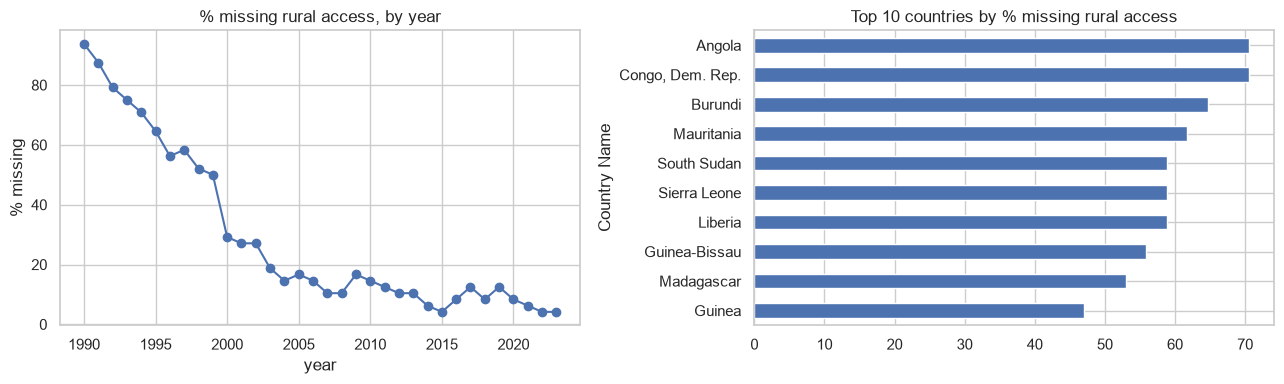

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df_ssa.groupby("year")["access_rural_pct"].apply(lambda x: x.isna().mean() * 100).plot(
    marker="o", ax=axes[0], title="% missing rural access, by year")
axes[0].set_ylabel("% missing")
(df_ssa.groupby("Country Name")["access_rural_pct"].apply(lambda x: x.isna().mean() * 100)
 .sort_values(ascending=False).head(10).sort_values().plot(kind="barh", ax=axes[1],
 title="Top 10 countries by % missing rural access"))
plt.tight_layout(); plt.show()

Early years have far more gaps (the household surveys behind the estimates are sparse before the mid-2000s). We restrict to **2007 onward**, as in the first analysis, where total and urban access are complete.

In [6]:
df = df_ssa[df_ssa["year"] >= 2007].copy()
print(df.shape)
(df[value_cols].isna().sum()).to_frame("missing count")

(816, 13)


,missing count
access_pct,0
access_urban_pct,0
access_rural_pct,77
urban_rural_gap,77
gdp_pc,21
urban_pop_pct,0
pop_growth,1
population,0
renewable_pct,78


### 2.3 Why are values missing? (MCAR, MAR or MNAR)
Missing data is not just a nuisance to drop: *why* it is missing decides whether dropping or filling it is safe.

| Type | Meaning | Consequence |
|---|---|---|
| **MCAR** (missing completely at random) | missingness unrelated to anything | dropping rows is safe |
| **MAR** (missing at random) | missingness depends on **other observed** variables (e.g. income group, year) | dropping can bias results unless those variables are accounted for |
| **MNAR** (missing not at random) | missingness depends on the **missing value itself** (e.g. the poorest-access countries do not report) | cannot be proven from the data; needs domain reasoning |

**How we test it.** For every variable that has gaps, we create a 0/1 "is missing" flag and test whether it is related to observed information:
chi-square tests against income group and time period, and Mann-Whitney tests comparing other observed variables between missing and non-missing rows (p < 0.05 means *related*).
Strictly, MCAR vs MAR can be tested this way, but **MAR vs MNAR cannot** be separated by data alone, so that part is argued from how the data is produced.
Note we run several tests, so a single p-value just under 0.05 should be read cautiously.

### Before modelling, the linear regression assumptions were tested on the training residuals. Linearity (Rainbow, p = 0.30), normality of residuals (Shapiro–Wilk, p = 0.052, borderline) and multicollinearity (max VIF = 2.30) were satisfied. Homoscedasticity was violated (Breusch–Pagan p = 0.016), so cluster-robust standard errors were used for inference. [Independence: add the corrected Durbin–Watson result here.] Because VIFs were low, Ridge regression was not needed to correct collinearity; it was retained as a regularised comparison and performed almost identically to ordinary least squares. To prevent leakage from repeated observations of the same country, train/test splits and cross-validation were done by country.

In [7]:
ms = df.copy()
ms["IncomeGroup"] = ms["IncomeGroup"].fillna("Unknown")
ms["period"] = pd.cut(ms["year"], bins=[2006, 2012, 2018, 2025], labels=["2007-12", "2013-18", "2019+"])
observed_vars = ["access_urban_pct", "urban_pop_pct", "pop_growth", "gdp_pc", "population"]

def missingness_tests(col):
    flag = ms[col].isna().astype(int)
    res = []
    for label, grp in [("income group", ms["IncomeGroup"]), ("time period", ms["period"])]:
        ct = pd.crosstab(grp, flag)
        p = st.chi2_contingency(ct)[1] if ct.shape[0] > 1 and ct.shape[1] > 1 else np.nan
        res.append((f"vs {label} (chi-square)", p))
    for v in observed_vars:
        if v == col:
            continue
        a, b = ms.loc[flag == 1, v].dropna(), ms.loc[flag == 0, v].dropna()
        p = st.mannwhitneyu(a, b).pvalue if len(a) > 5 and len(b) > 5 else np.nan
        res.append((f"vs {v} (Mann-Whitney)", p))
    out = pd.DataFrame(res, columns=["Test", "p-value"])
    out["Related?"] = np.where(out["p-value"] < 0.05, "yes", "no")
    return out

for col in ["access_rural_pct", "renewable_pct", "gdp_pc", "urban_pop_pct", "pop_growth", "population"]:
    n = int(ms[col].isna().sum())
    if n == 0:
        print(f"\n=== {col}: no missing values ===")
        continue
    t = missingness_tests(col)
    related = t.loc[t["p-value"] < 0.05, "Test"].tolist()
    print(f"\n=== {col}: {n} missing ({n / len(ms):.1%}) ===")
    display(t.round(4))
    if related:
        print("Verdict: missingness IS related to observed variables ->", related)
        print("         consistent with MAR (or MNAR; the data alone cannot tell these two apart).")
    else:
        print("Verdict: no detectable relationship with observed variables -> consistent with MCAR.")


=== access_rural_pct: 77 missing (9.4%) ===


,Test,p-value,Related?
0,vs income group (chi-square),0.0005,yes
1,vs time period (chi-square),0.0770,no
2,vs access_urban_pct (Mann-Whitney),0.0000,yes
3,vs urban_pop_pct (Mann-Whitney),0.6859,no
4,vs pop_growth (Mann-Whitney),0.0000,yes
5,vs gdp_pc (Mann-Whitney),0.0010,yes
6,vs population (Mann-Whitney),0.0465,yes


Verdict: missingness IS related to observed variables -> ['vs income group (chi-square)', 'vs access_urban_pct (Mann-Whitney)', 'vs pop_growth (Mann-Whitney)', 'vs gdp_pc (Mann-Whitney)', 'vs population (Mann-Whitney)']
         consistent with MAR (or MNAR; the data alone cannot tell these two apart).

=== renewable_pct: 78 missing (9.6%) ===


,Test,p-value,Related?
0,vs income group (chi-square),0.9422,no
1,vs time period (chi-square),0.0000,yes
2,vs access_urban_pct (Mann-Whitney),0.0001,yes
3,vs urban_pop_pct (Mann-Whitney),0.1334,no
4,vs pop_growth (Mann-Whitney),0.1824,no
5,vs gdp_pc (Mann-Whitney),0.0040,yes
6,vs population (Mann-Whitney),0.0186,yes


Verdict: missingness IS related to observed variables -> ['vs time period (chi-square)', 'vs access_urban_pct (Mann-Whitney)', 'vs gdp_pc (Mann-Whitney)', 'vs population (Mann-Whitney)']
         consistent with MAR (or MNAR; the data alone cannot tell these two apart).

=== gdp_pc: 21 missing (2.6%) ===


,Test,p-value,Related?
0,vs income group (chi-square),0.0000,yes
1,vs time period (chi-square),0.0328,yes
2,vs access_urban_pct (Mann-Whitney),0.0040,yes
3,vs urban_pop_pct (Mann-Whitney),0.0002,yes
4,vs pop_growth (Mann-Whitney),0.0000,yes
5,vs population (Mann-Whitney),0.0226,yes


Verdict: missingness IS related to observed variables -> ['vs income group (chi-square)', 'vs time period (chi-square)', 'vs access_urban_pct (Mann-Whitney)', 'vs urban_pop_pct (Mann-Whitney)', 'vs pop_growth (Mann-Whitney)', 'vs population (Mann-Whitney)']
         consistent with MAR (or MNAR; the data alone cannot tell these two apart).

=== urban_pop_pct: no missing values ===

=== pop_growth: 1 missing (0.1%) ===


,Test,p-value,Related?
0,vs income group (chi-square),0.0000,yes
1,vs time period (chi-square),0.3008,no
2,vs access_urban_pct (Mann-Whitney),NaN,no
3,vs urban_pop_pct (Mann-Whitney),NaN,no
4,vs gdp_pc (Mann-Whitney),NaN,no
5,vs population (Mann-Whitney),NaN,no


Verdict: missingness IS related to observed variables -> ['vs income group (chi-square)']
         consistent with MAR (or MNAR; the data alone cannot tell these two apart).

=== population: no missing values ===


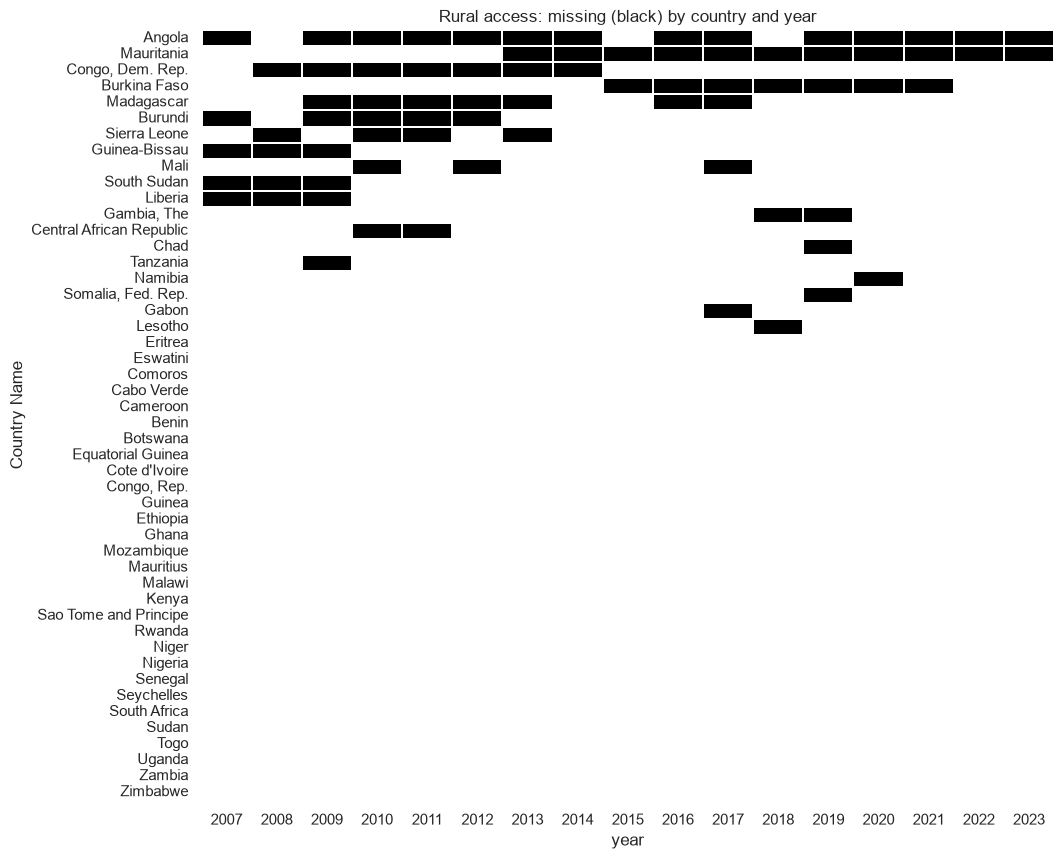

Countries with rural access missing in EVERY year since 2007: none
Share of all missing cells that come from the 5 worst countries: 60%

Share of rural access missing, by income group:


,share missing
IncomeGroup,
High income,0.000
Low income,0.134
Lower middle income,0.082
Upper middle income,0.010


In [8]:
# Where exactly is rural access missing? Country-by-year map (black = missing)
flag_map = (ms.assign(m=ms["access_rural_pct"].isna().astype(int))
              .pivot(index="Country Name", columns="year", values="m"))
order = flag_map.sum(axis=1).sort_values(ascending=False).index
plt.figure(figsize=(11, 10))
sns.heatmap(flag_map.loc[order], cmap="Greys", cbar=False, linewidths=.2, linecolor="white")
plt.title("Rural access: missing (black) by country and year"); plt.show()

by_country = ms.groupby("Country Name")["access_rural_pct"].apply(lambda s: s.isna().mean()).sort_values(ascending=False)
always = by_country[by_country == 1].index.tolist()
print("Countries with rural access missing in EVERY year since 2007:", always if always else "none")
print("Share of all missing cells that come from the 5 worst countries:",
      f"{ms.loc[ms['Country Name'].isin(by_country.head(5).index), 'access_rural_pct'].isna().sum() / max(ms['access_rural_pct'].isna().sum(), 1):.0%}")
missing_by_group = ms.groupby("IncomeGroup")["access_rural_pct"].apply(lambda s: s.isna().mean()).round(3)
print("\nShare of rural access missing, by income group:"); display(missing_by_group.to_frame("share missing"))

**What the missingness pattern means, and how we handle it** (read your results above, then confirm or adjust this reasoning):

- Rural access figures come from **household surveys and censuses**. Where no recent survey exists, the World Bank does not publish a value. Missingness is therefore tied to a country's *survey coverage*, which is often related to income level, conflict or data-system capacity. That points to **MAR at least**, and possibly **MNAR** if the countries with the worst rural access are also the ones that do not report.
- **Target (the gap):** we **never impute it**. Filling in rural access would invent the very number we are trying to predict. Rows without it are dropped.
- **Predictors:** short gaps (up to 2 years inside a country's series) are **interpolated**, because GDP, urbanisation and population change smoothly. Anything longer is dropped, not guessed.
- **Consequence for the conclusions:** the model describes countries **with published survey data**. If those are systematically better-off or better-governed, the true gap in non-reporting countries may be larger. Section 3 checks how much the dropping changes the sample mix.

### 2.4 Descriptive statistics

In [9]:
df[value_cols].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
access_pct,816.0,43.89,25.95,0.80,20.38,42.90,61.02,1.000000e+02
access_urban_pct,816.0,69.88,22.19,3.50,57.18,74.10,87.10,1.000000e+02
access_rural_pct,739.0,27.59,27.11,0.40,6.00,19.50,37.50,1.000000e+02
urban_rural_gap,739.0,43.58,21.07,-8.20,29.55,46.20,57.65,8.890000e+01
gdp_pc,795.0,2408.70,3190.22,166.16,690.44,1121.20,2314.08,1.914151e+04
urban_pop_pct,816.0,41.29,16.55,9.77,29.16,39.97,52.32,9.164000e+01
pop_growth,815.0,2.40,1.04,-5.42,1.97,2.57,2.98,5.410000e+00
population,816.0,21474568.46,32933702.98,85033.00,2423420.50,12137545.00,24271921.00,2.278829e+08
renewable_pct,738.0,64.32,26.62,0.70,46.20,74.85,84.42,9.720000e+01


**Skewness and shape.** Large skew in a variable (GDP per capita and population usually) is a signal that a log transform may help linearity later.

In [10]:
pd.DataFrame({"skew": df[value_cols].skew().round(2), "kurtosis": df[value_cols].kurt().round(2)})

,skew,kurtosis
access_pct,0.38,-0.71
access_urban_pct,-0.82,0.07
access_rural_pct,1.26,0.72
urban_rural_gap,-0.38,-0.42
gdp_pc,2.67,7.73
urban_pop_pct,0.47,-0.14
pop_growth,-1.29,5.37
population,3.48,14.64
renewable_pct,-0.88,-0.36


### 2.5 Exploration: access, the gap, and country stories

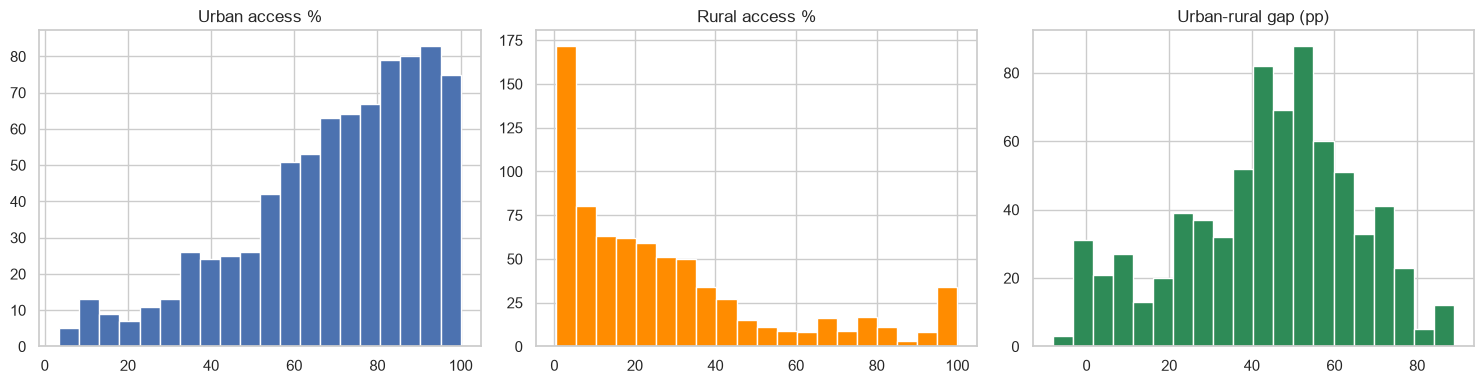

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["access_urban_pct"].dropna().hist(bins=20, ax=axes[0]); axes[0].set_title("Urban access %")
df["access_rural_pct"].dropna().hist(bins=20, ax=axes[1], color="darkorange"); axes[1].set_title("Rural access %")
df["urban_rural_gap"].dropna().hist(bins=20, ax=axes[2], color="seagreen"); axes[2].set_title("Urban-rural gap (pp)")
plt.tight_layout(); plt.show()

Urban access is piled up near 75–100%, while rural access is spread over 0–100% with most mass at the low end. The gap itself is wide (mean about 44 percentage points).

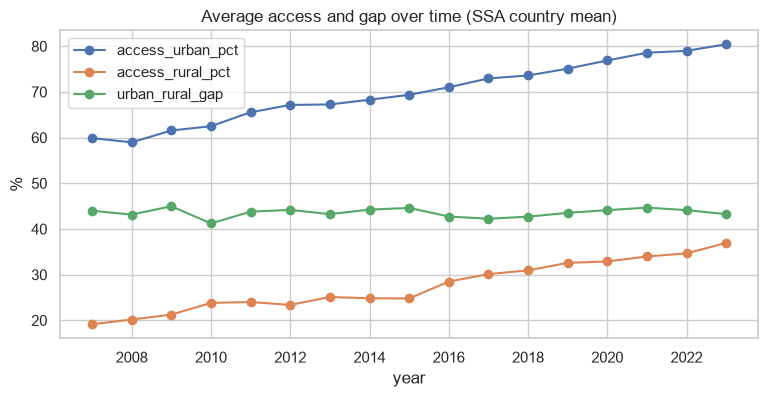

In [12]:
trend = df.groupby("year")[["access_urban_pct", "access_rural_pct", "urban_rural_gap"]].mean()
trend.plot(marker="o", figsize=(9, 4), title="Average access and gap over time (SSA country mean)")
plt.ylabel("%"); plt.show()

In [13]:
neg = df[df["urban_rural_gap"] < 0][["Country Name", "year", "access_urban_pct", "access_rural_pct", "urban_rural_gap"]]
top = df.sort_values("urban_rural_gap", ascending=False).head(5)[["Country Name", "year", "access_urban_pct", "access_rural_pct", "urban_rural_gap"]]
print("Country-years where rural >= urban:"); display(neg)
print("Largest gaps:"); display(top)

Country-years where rural >= urban:


,Country Name,year,access_urban_pct,access_rural_pct,urban_rural_gap
1275,Mauritius,2016,99.6,99.8,-0.2
1334,Sao Tome and Principe,2017,73.5,76.2,-2.7
1371,Mauritius,2018,99.5,100.0,-0.5
1467,Mauritius,2020,99.4,99.5,-0.1
1485,South Africa,2020,87.3,95.5,-8.2
1499,Cabo Verde,2021,94.9,96.9,-2.0
1515,Mauritius,2021,99.3,99.8,-0.5
1533,South Africa,2021,87.4,93.4,-6.0
1547,Cabo Verde,2022,95.3,97.4,-2.1
1563,Mauritius,2022,99.0,100.0,-1.0


Largest gaps:


,Country Name,year,access_urban_pct,access_rural_pct,urban_rural_gap
1507,Equatorial Guinea,2021,90.3,1.4,88.9
1459,Equatorial Guinea,2020,90.5,1.8,88.7
1411,Equatorial Guinea,2019,90.8,2.4,88.4
1555,Equatorial Guinea,2022,89.8,1.4,88.4
1363,Equatorial Guinea,2018,91.0,2.9,88.1


- **Negative gaps** are mostly small, relatively wealthy countries (e.g. Mauritius, Cabo Verde, South Africa) where both urban and rural access are near-universal, so the sign flips on survey noise.
- **Equatorial Guinea** is the extreme case: about 90% urban versus 1–3% rural, i.e. oil wealth that did not reach rural areas.

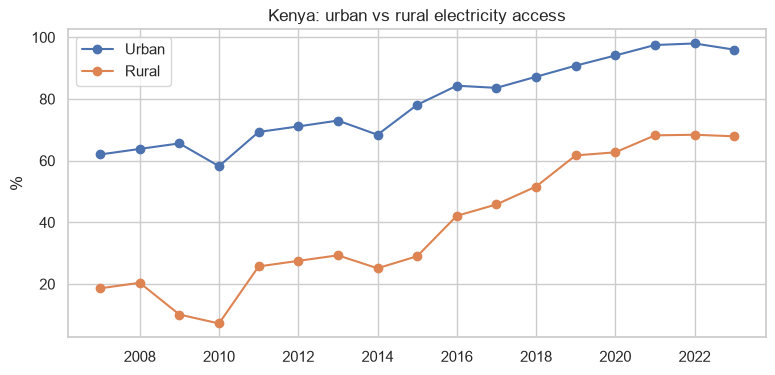

In [14]:
kenya = df[df["Country Name"] == "Kenya"].sort_values("year")
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(kenya["year"], kenya["access_urban_pct"], marker="o", label="Urban")
ax.plot(kenya["year"], kenya["access_rural_pct"], marker="o", label="Rural")
ax.set_title("Kenya: urban vs rural electricity access"); ax.set_ylabel("%"); ax.legend(); plt.show()

Kenya's rural access rises steeply after about 2015 and the gap narrows. The timing is *consistent with* the expansion of off-grid solar and mini-grids and national grid programmes, but this data cannot prove the cause. Note the dips in 2009–2010: they look like survey-to-survey noise rather than real events.

**Correlation with candidate predictors** (before any modelling):

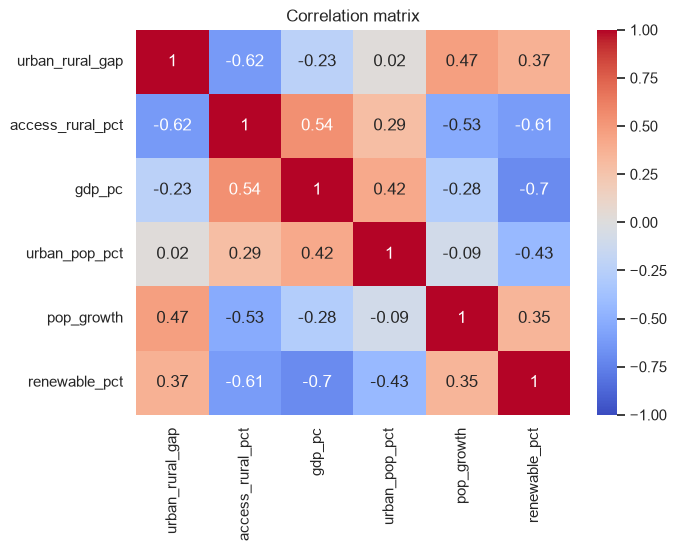

In [15]:
pred_cols = ["gdp_pc", "urban_pop_pct", "pop_growth", "renewable_pct"]
corr = df[["urban_rural_gap", "access_rural_pct"] + pred_cols].corr(numeric_only=True).round(2)
plt.figure(figsize=(7, 5)); sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix"); plt.show()

## 3. Data Preparation

Steps:
1. **Predictor missing values:** interpolate within each country (max 2 consecutive years, no extrapolation), because these indicators are smooth over time. Anything still missing is dropped.
2. **Target missing values:** rows without a gap value are dropped (we never impute the target).
3. **Transform:** `log_gdp_pc` (GDP per capita is strongly right-skewed).
4. **Scaling:** done inside the modelling pipeline (fit on training data only to avoid leakage).
5. **Keep the country as a grouping key** so the train/test split can keep whole countries together (see Section 4).

In [16]:
model_cols = ["Country Name", "Country Code", "IncomeGroup", "year", "access_urban_pct", "access_rural_pct",
              "urban_rural_gap", "gdp_pc", "urban_pop_pct", "pop_growth", "population", "renewable_pct"]
dfm = df[model_cols].sort_values(["Country Name", "year"]).copy()

fill_cols = ["gdp_pc", "urban_pop_pct", "pop_growth", "population", "renewable_pct"]
dfm[fill_cols] = (dfm.groupby("Country Name")[fill_cols]
                  .transform(lambda s: s.interpolate(limit=2, limit_area="inside")))

before = len(dfm)
dfm = dfm.dropna(subset=["urban_rural_gap"] + fill_cols).copy()
print(f"Rows kept: {len(dfm)} of {before}  ({dfm['Country Name'].nunique()} countries)")

dfm["log_gdp_pc"] = np.log(dfm["gdp_pc"])
dfm["log_population"] = np.log(dfm["population"])

FEATURES = ["log_gdp_pc", "urban_pop_pct", "pop_growth", "renewable_pct"]
TARGET = "urban_rural_gap"
dfm.to_csv("ssa_model_data.csv", index=False)       # used by the dashboard
dfm[["Country Name", "year", TARGET] + FEATURES].describe().round(2).T

Rows kept: 651 of 816  (48 countries)


,count,mean,std,min,25%,50%,75%,max
year,651.0,2014.27,4.49,2007.00,2010.00,2014.00,2018.00,2022.00
urban_rural_gap,651.0,43.91,20.85,-8.20,29.90,46.40,57.70,88.90
log_gdp_pc,651.0,7.25,0.99,5.24,6.55,7.02,7.77,9.86
urban_pop_pct,651.0,41.18,16.44,10.11,29.60,40.33,51.74,90.79
pop_growth,651.0,2.37,0.95,-2.63,1.96,2.54,2.96,4.61
renewable_pct,651.0,63.80,26.87,0.70,45.70,74.30,83.90,97.20


In [17]:
# Sensitivity check: did dropping rows change the sample mix?
dropped = len(df) - len(dfm)
print(f"Rows dropped for missing values: {dropped} of {len(df)} ({dropped / len(df):.0%})")
mix = pd.DataFrame({
    "All SSA rows 2007+": df["IncomeGroup"].fillna("Unknown").value_counts(normalize=True),
    "Rows kept for modelling": dfm["IncomeGroup"].fillna("Unknown").value_counts(normalize=True),
}).fillna(0).round(3)
display(mix)
print("Mean urban access, all vs kept:", round(df["access_urban_pct"].mean(), 1), "vs", round(dfm["access_urban_pct"].mean(), 1))
print("Mean urban-rural gap, kept rows:", round(dfm["urban_rural_gap"].mean(), 1))
print("Large shifts in this table mean the modelled countries are not representative of all of Sub-Saharan Africa.")

Rows dropped for missing values: 165 of 816 (20%)


,All SSA rows 2007+,Rows kept for modelling
IncomeGroup,,
High income,0.021,0.025
Low income,0.438,0.404
Lower middle income,0.417,0.432
Upper middle income,0.125,0.140


Mean urban access, all vs kept: 69.9 vs 70.8
Mean urban-rural gap, kept rows: 43.9
Large shifts in this table mean the modelled countries are not representative of all of Sub-Saharan Africa.


## 4. Modelling

### 4.1 Train/test split by **country**
Each country appears in many years, and a country's values in one year are strongly related to its values in the next. A plain random split would put 2019 in training and 2020 in test for the same country, which leaks information and inflates R². We therefore split **by country** (`GroupShuffleSplit`): the test set contains countries the model has never seen, which is also the real-world use case (predicting for a new country).

In [18]:
X, y, groups = dfm[FEATURES], dfm[TARGET], dfm["Country Name"]
gss = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)
train_idx, test_idx = next(gss.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]
print("Train rows:", len(X_train), "| countries:", g_train.nunique())
print("Test rows:", len(X_test), "| countries:", groups.iloc[test_idx].nunique())

Train rows: 490 | countries: 36
Test rows: 161 | countries: 12


### 4.2 Testing the linear regression assumptions (before trusting the model)
We fit a baseline OLS on the **training data** and test each assumption on its residuals.

| Assumption | Check used | Passes when |
|---|---|---|
| Linearity | Residuals-vs-fitted plot, Rainbow test | no curve; p > 0.05 |
| Independence of errors | Durbin–Watson on residuals ordered by country, then year | about 2 (1.5–2.5) |
| Homoscedasticity (constant variance) | Breusch–Pagan | p > 0.05 |
| Normality of residuals | Q–Q plot, Shapiro–Wilk | points on line; p > 0.05 |
| No multicollinearity | Variance Inflation Factor | VIF < 5 (concern above 10) |

In [19]:
Xc = sm.add_constant(X_train)
ols = sm.OLS(y_train, Xc).fit()
print(ols.summary().tables[1])
resid, fitted = ols.resid, ols.fittedvalues

                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const           -20.4365     10.147     -2.014      0.045     -40.374      -0.499
log_gdp_pc        4.0301      1.213      3.324      0.001       1.648       6.413
urban_pop_pct     0.0746      0.055      1.346      0.179      -0.034       0.184
pop_growth       10.2313      0.811     12.614      0.000       8.638      11.825
renewable_pct     0.1609      0.041      3.927      0.000       0.080       0.241


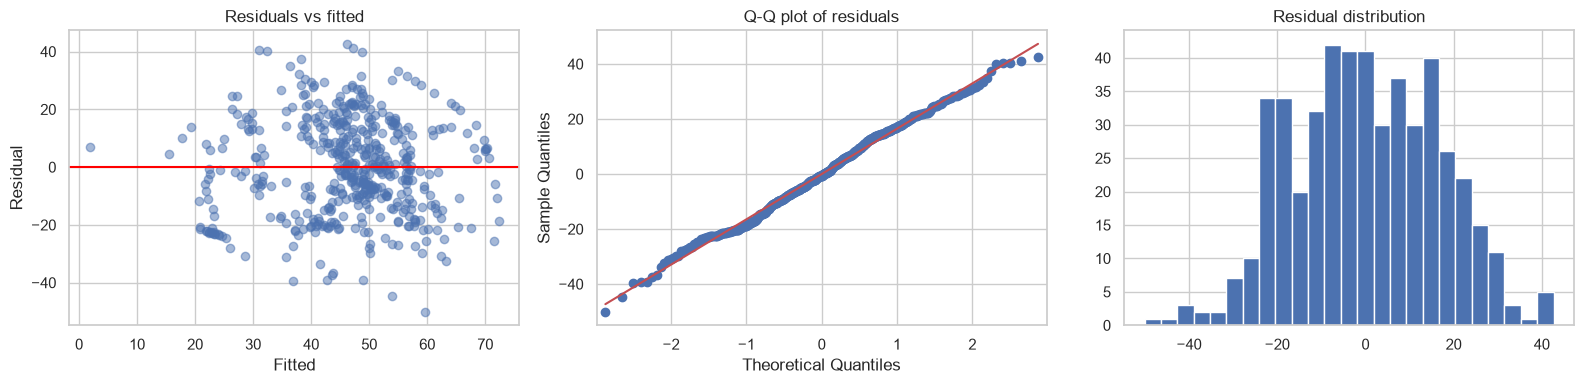

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(fitted, resid, alpha=.5); axes[0].axhline(0, color="red")
axes[0].set(title="Residuals vs fitted", xlabel="Fitted", ylabel="Residual")
sm.qqplot(resid, line="s", ax=axes[1]); axes[1].set_title("Q-Q plot of residuals")
axes[2].hist(resid, bins=25); axes[2].set_title("Residual distribution")
plt.tight_layout(); plt.show()

In [21]:
rows = []
# 1) Linearity
rb_stat, rb_p = linear_rainbow(ols)
rows.append(("Linearity (Rainbow)", f"p = {rb_p:.4f}", rb_p > 0.05))
# 2) Independence
# Order residuals by country, then year, so neighbours are consecutive years of the SAME country
order = dfm.loc[X_train.index].sort_values(["Country Name", "year"]).index
dw = durbin_watson(resid.loc[order])
rows.append(("Independence (Durbin-Watson, by country-year)", f"DW = {dw:.2f}", 1.5 <= dw <= 2.5))
# 3) Homoscedasticity
bp_lm, bp_p, _, _ = het_breuschpagan(resid, Xc)
rows.append(("Homoscedasticity (Breusch-Pagan)", f"p = {bp_p:.4f}", bp_p > 0.05))
# 4) Normality
sh_stat, sh_p = st.shapiro(resid.sample(min(len(resid), 5000), random_state=RANDOM_STATE))
rows.append(("Normality (Shapiro-Wilk)", f"p = {sh_p:.4f}", sh_p > 0.05))
# 5) Multicollinearity
vif = pd.DataFrame({"feature": X_train.columns,
                    "VIF": [variance_inflation_factor(Xc.values, i + 1) for i in range(X_train.shape[1])]})
max_vif = vif["VIF"].max()
rows.append(("Multicollinearity (max VIF)", f"{max_vif:.2f}", max_vif < 5))

report = pd.DataFrame(rows, columns=["Assumption", "Statistic", "Passed"])
report["Verdict"] = np.where(report["Passed"], "PASS", "FAIL")
display(report[["Assumption", "Statistic", "Verdict"]])
display(vif.round(2))

,Assumption,Statistic,Verdict
0,Linearity (Rainbow),p = 0.2957,PASS
1,"Independence (Durbin-Watson, by country-year)",DW = 0.35,FAIL
2,Homoscedasticity (Breusch-Pagan),p = 0.0155,FAIL
3,Normality (Shapiro-Wilk),p = 0.0522,PASS
4,Multicollinearity (max VIF),2.30,PASS


,feature,VIF
0,log_gdp_pc,2.30
1,urban_pop_pct,1.48
2,pop_growth,1.13
3,renewable_pct,1.95


### Interpretation of the assumption tests

**Independence of errors fails** (Durbin–Watson = 0.35 when residuals are ordered by country and year; a value near 2 indicates independence). A country's residuals stay similar from one year to the next, because the same unmeasured factors keep pushing a country above or below the model's prediction year after year.

**What this means**
- Rows from the same country are not independent. The effective sample size is closer to the number of countries (about 48) than to the number of rows (about 650).
- Ordinary standard errors and p-values are too optimistic. This is why **cluster-robust standard errors (clustered by country)** are reported, and why the **country-wise train/test split and country-grouped cross-validation** were used.
- It also helps explain why cross-validation scores varied widely from fold to fold.

**Homoscedasticity also fails** (Breusch–Pagan p = 0.016), which further weakens conventional standard errors. Linearity (Rainbow p = 0.30), normality (Shapiro–Wilk p = 0.052, borderline) and multicollinearity (max VIF = 2.30) pass.

### 4.3 Remedies
The tests above decide what we do next. The code below prints which remedies apply, based on the results rather than assuming them:

- **Multicollinearity (high VIF)** → **Ridge (L2) regression**, which shrinks correlated coefficients. It needs **standardised** inputs, so we scale first.
- **Skewed predictors / non-linearity** → we already log-transformed GDP per capita.
- **Non-constant variance or non-normal errors** → affect confidence intervals more than predictions; we report **cluster-robust standard errors** (clustered by country) for inference.
- **Autocorrelated errors** (panel data) → handled in the design through the **country-wise split**, plus cluster-robust errors.

In [22]:
failed = report.loc[~report["Passed"], "Assumption"].tolist()
print("Assumptions failed:", failed if failed else "none")
if any("Multicollinearity" in f for f in failed):
    print("-> Ridge regression is justified (collinear predictors).")
else:
    print("-> VIF is acceptable; Ridge is still fitted as a regularised comparison to guard against overfitting.")
if any("Homoscedasticity" in f or "Normality" in f for f in failed):
    print("-> Use cluster-robust standard errors for inference (below).")
if any("Independence" in f for f in failed):
    print("-> Errors are autocorrelated (repeated country-years); evaluation uses unseen countries.")

robust = sm.OLS(y_train, Xc).fit(cov_type="cluster", cov_kwds={"groups": g_train.values})
print()
print(robust.summary().tables[1])

Assumptions failed: ['Independence (Durbin-Watson, by country-year)', 'Homoscedasticity (Breusch-Pagan)']
-> VIF is acceptable; Ridge is still fitted as a regularised comparison to guard against overfitting.
-> Use cluster-robust standard errors for inference (below).
-> Errors are autocorrelated (repeated country-years); evaluation uses unseen countries.

                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
const           -20.4365     21.177     -0.965      0.335     -61.943      21.070
log_gdp_pc        4.0301      3.106      1.297      0.194      -2.058      10.118
urban_pop_pct     0.0746      0.167      0.446      0.655      -0.253       0.402
pop_growth       10.2313      2.544      4.022      0.000       5.246      15.217
renewable_pct     0.1609      0.114      1.412      0.158      -0.062       0.384


### 4.4 Training and comparing four models
The requirement is at least three models, so we compare:

| Model | Why it is included |
|---|---|
| **Linear Regression** | the baseline asked for in the brief; needs the assumptions tested above |
| **Ridge (L2)** | regularised linear model (remedy for collinearity / overfitting) |
| **Random Forest** | non-linear; no linearity or normality assumptions; tests whether non-linearity helps |
| **Gradient Boosting** | a second non-linear model, often stronger on small tabular data |

All hyper-parameters are tuned with **country-grouped cross-validation on the training countries only** (`GroupKFold`), so no information from the test countries leaks in.
The **best model is selected by the lowest cross-validated MSE**, and the test set is used once, for the final report.

In [23]:
alphas = np.logspace(-3, 3, 50)
cv = list(GroupKFold(n_splits=5).split(X_train, y_train, g_train))
neg_mse = "neg_mean_squared_error"

lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas, cv=cv)).fit(X_train, y_train)
best_alpha = ridge[-1].alpha_

rf_search = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    {"n_estimators": [200], "max_depth": [3, 5, None], "min_samples_leaf": [5, 10, 20]},
    cv=cv, scoring=neg_mse).fit(X_train, y_train)

gb_search = GridSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    {"n_estimators": [100, 200], "max_depth": [2, 3], "learning_rate": [0.03, 0.1], "subsample": [0.8]},
    cv=cv, scoring=neg_mse).fit(X_train, y_train)

fitted = {
    "Linear Regression": lin,
    "Ridge": ridge,
    "Random Forest": rf_search.best_estimator_,
    "Gradient Boosting": gb_search.best_estimator_,
}
cv_mse = {
    "Linear Regression": -cross_val_score(make_pipeline(StandardScaler(), LinearRegression()),
                                          X_train, y_train, cv=cv, scoring=neg_mse).mean(),
    "Ridge": -cross_val_score(make_pipeline(StandardScaler(), Ridge(alpha=best_alpha)),
                              X_train, y_train, cv=cv, scoring=neg_mse).mean(),
    "Random Forest": -rf_search.best_score_,
    "Gradient Boosting": -gb_search.best_score_,
}
print(f"Ridge alpha (grouped CV): {best_alpha:.3f}")
print("Random Forest best params:", rf_search.best_params_)
print("Gradient Boosting best params:", gb_search.best_params_)

Ridge alpha (grouped CV): 244.205
Random Forest best params: {'max_depth': None, 'min_samples_leaf': 20, 'n_estimators': 200}
Gradient Boosting best params: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.8}


## 5. Evaluation

### 5.1 R² and MSE: what each tells you
- **MSE (Mean Squared Error)** = average of (actual − predicted)². It is in the *squared units of the target* (here percentage-points²), so it is hard to read directly (its square root, **RMSE**, is back in percentage points). It punishes large errors heavily and is useful for **comparing models on the same data**. Lower is better; 0 is perfect.
- **R² (coefficient of determination)** = 1 − (model error ÷ error of just predicting the average). It is **unit-free**, usually between 0 and 1, and reads as *the share of the variation in the gap that the model explains*. On unseen data it can be **negative**, meaning the model is worse than predicting the mean.

**Key difference:** MSE measures *how large the errors are* (in squared units and tied to the scale of the target), while R² measures *how much better the model is than a naive average prediction* (a relative, scale-free score). A model can have a small MSE but a low R² if the target barely varies, so we report both.

In [24]:
def scores(model, Xa, ya):
    p = model.predict(Xa)
    mse = mean_squared_error(ya, p)
    return {"R2": r2_score(ya, p), "MSE": mse, "RMSE": np.sqrt(mse)}

baseline = np.full(len(y_test), y_train.mean())
rows = {"Mean-only baseline (test)": {"R2": r2_score(y_test, baseline),
                                      "MSE": mean_squared_error(y_test, baseline),
                                      "RMSE": np.sqrt(mean_squared_error(y_test, baseline))}}
for name, m in fitted.items():
    rows[f"{name} (train)"] = scores(m, X_train, y_train)
    rows[f"{name} (test)"] = scores(m, X_test, y_test)
results = pd.DataFrame(rows).T.round(3)
results

,R2,MSE,RMSE
Mean-only baseline (test),-0.192,581.087,24.106
Linear Regression (train),0.310,271.295,16.471
Linear Regression (test),0.035,470.291,21.686
Ridge (train),0.273,285.977,16.911
Ridge (test),0.030,472.750,21.743
Random Forest (train),0.732,105.476,10.270
Random Forest (test),-0.336,651.565,25.526
Gradient Boosting (train),0.974,10.286,3.207
Gradient Boosting (test),-0.261,614.663,24.792


### 5.2 Model comparison and selection of the best model

,CV MSE (train countries),Train R2,Test R2,Test MSE,Test RMSE
Linear Regression,349.981,0.310,0.035,470.291,21.686
Ridge,368.286,0.273,0.030,472.750,21.743
Random Forest,369.071,0.732,-0.336,651.565,25.526
Gradient Boosting,425.290,0.974,-0.261,614.663,24.792


Selected model (lowest country-grouped CV MSE): Linear Regression


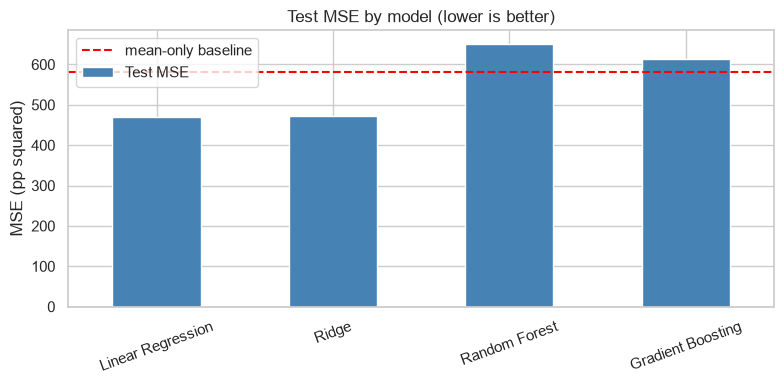

In [25]:
comp = pd.DataFrame({
    name: {"CV MSE (train countries)": cv_mse[name],
           "Train R2": r2_score(y_train, m.predict(X_train)),
           "Test R2": r2_score(y_test, m.predict(X_test)),
           "Test MSE": mean_squared_error(y_test, m.predict(X_test)),
           "Test RMSE": np.sqrt(mean_squared_error(y_test, m.predict(X_test)))}
    for name, m in fitted.items()}).T.round(3)

best_name = comp["CV MSE (train countries)"].idxmin()
best_model = fitted[best_name]
display(comp)
print("Selected model (lowest country-grouped CV MSE):", best_name)
comp.to_csv("model_comparison.csv")

ax = comp["Test MSE"].plot(kind="bar", figsize=(8, 4), color="steelblue", title="Test MSE by model (lower is better)")
ax.axhline(mean_squared_error(y_test, baseline), color="red", ls="--", label="mean-only baseline")
ax.set_ylabel("MSE (pp squared)"); ax.legend(); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

Linear Regression: R2 across 5 country-grouped folds: [ 0.224  0.24  -0.203  0.105  0.381] | mean: 0.15


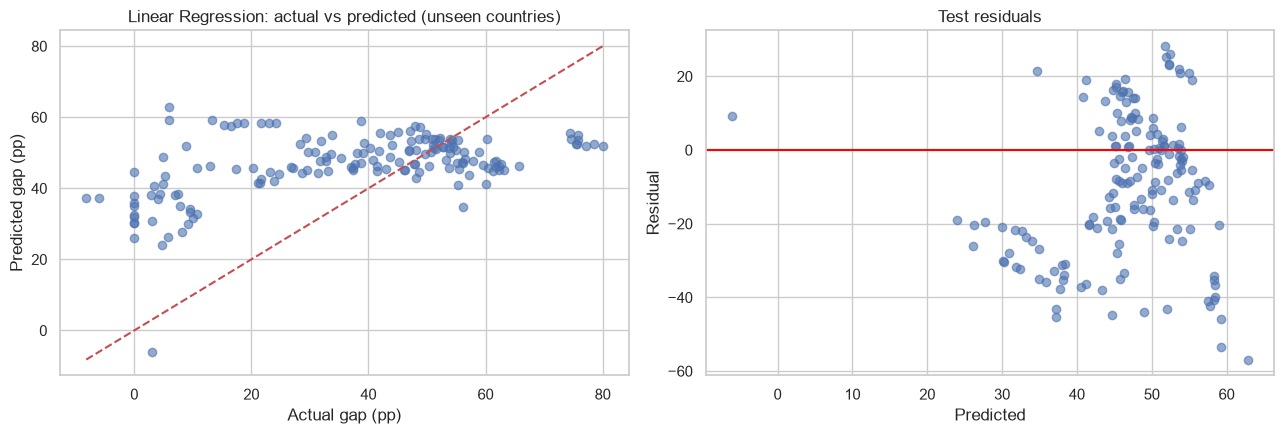

In [26]:
gkf_r2 = cross_val_score(clone(best_model), X, y, groups=groups, cv=GroupKFold(n_splits=5), scoring="r2")
print(f"{best_name}: R2 across 5 country-grouped folds:", gkf_r2.round(3), "| mean:", gkf_r2.mean().round(3))

pred = best_model.predict(X_test)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(y_test, pred, alpha=.6)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
axes[0].plot(lims, lims, "r--"); axes[0].set(xlabel="Actual gap (pp)", ylabel="Predicted gap (pp)",
                                            title=f"{best_name}: actual vs predicted (unseen countries)")
axes[1].scatter(pred, y_test - pred, alpha=.6); axes[1].axhline(0, color="red")
axes[1].set(xlabel="Predicted", ylabel="Residual", title="Test residuals")
plt.tight_layout(); plt.show()

### 5.3 What drives the gap?

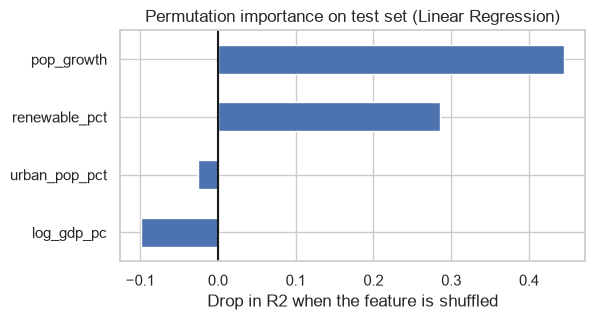

Standardised coefficients of the linear models (effect in pp per 1 std dev of the predictor):


,Linear,Ridge
log_gdp_pc,3.772,1.129
urban_pop_pct,1.227,1.356
pop_growth,10.048,6.685
renewable_pct,4.100,2.237


In [27]:
perm = permutation_importance(best_model, X_test, y_test, n_repeats=30, random_state=RANDOM_STATE, scoring="r2")
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
imp.plot(kind="barh", figsize=(6, 3), title=f"Permutation importance on test set ({best_name})")
plt.axvline(0, color="k"); plt.xlabel("Drop in R2 when the feature is shuffled"); plt.show()

coefs = pd.DataFrame({"Linear": lin[-1].coef_, "Ridge": ridge[-1].coef_}, index=FEATURES).round(3)
print("Standardised coefficients of the linear models (effect in pp per 1 std dev of the predictor):")
coefs

### 5.4 Interpretation and limitations
Read the tables above against the business question, then write your conclusions here. Points to cover:

- **Do the models beat the mean-only baseline on unseen countries?** (compare test R² / MSE with the baseline row)
- **Overfitting check:** a large gap between train and test R² means the model memorises countries (tree models are especially prone).
- **Do non-linear models help?** If Random Forest / Gradient Boosting are not clearly better than Linear/Ridge, the weak fit is a lack of signal in the predictors, not a lack of model flexibility.
- **Ridge vs OLS:** if they are close, multicollinearity was not a major problem.
- **Which predictors matter, and in which direction?**
- **Missing data:** how the missingness findings in Section 2.3 limit who the conclusions apply to.
- **Limits:** associations, not causes; few countries; survey-based estimates carry noise; policy, geography, conflict and grid investment are not captured.
- **Next steps:** add policy or investment variables (e.g. off-grid solar sales, Mission 300 commitments) and model the *change* in the gap over time.

### With cluster-robust standard errors (by country), only population growth was a statistically significant predictor of the urban–rural gap (β ≈ 10.2 pp per percentage point of annual growth, p < 0.001). GDP per capita, urbanisation and renewable share were not significant, so their apparent contributions to prediction should be interpreted cautiously. This is consistent with the argument that rapid, largely rural population growth outpaces new electricity connections, although the result is an association and not proof of cause.

## 6. Deployment

Two tools are delivered:

1. **The model:** the best model is saved as a pickle file, `best_model.pkl` (below).
2. **The dashboard:** a **Power BI** report built on `ssa_powerbi_data.csv` and `model_comparison.csv` (both written below; see `PowerBI_Dashboard_Guide.md`). An interactive Streamlit version (`app.py`) is also included.

In [28]:
artifact = {
    "model": best_model,
    "model_name": best_name,
    "features": FEATURES,
    "target": TARGET,
    "test_metrics": comp.loc[best_name].to_dict(),
    "sklearn_version": sklearn.__version__,
    "note": "Predicts the urban-rural electricity-access gap (percentage points). Features: log GDP per capita, "
            "urban population %, population growth %, renewable share of final energy %.",
}
with open("best_model.pkl", "wb") as f:
    pickle.dump(artifact, f)

# Prove the pickle works: reload it and predict for a typical country-year
with open("best_model.pkl", "rb") as f:
    loaded = pickle.load(f)
example = pd.DataFrame([dfm[loaded["features"]].median()])
print(f"Loaded '{loaded['model_name']}' from best_model.pkl")
print("Predicted gap for a median country-year:", round(float(loaded["model"].predict(example)[0]), 1), "percentage points")

Loaded 'Linear Regression' from best_model.pkl
Predicted gap for a median country-year: 48.9 percentage points


In [29]:
# Files for the Power BI dashboard
export = dfm.copy()
export["split"] = np.where(export.index.isin(X_train.index), "train", "test")
export["predicted_gap"] = best_model.predict(export[FEATURES]).round(2)
export["residual"] = (export[TARGET] - export["predicted_gap"]).round(2)
export.to_csv("ssa_powerbi_data.csv", index=False)
print("Wrote ssa_powerbi_data.csv", export.shape, "and model_comparison.csv")

Wrote ssa_powerbi_data.csv (651, 17) and model_comparison.csv


**To run the Streamlit dashboard:**
```
pip install streamlit plotly scikit-learn pandas
streamlit run app.py
```
Run the notebook first so `ssa_model_data.csv`, `best_model.pkl` and `model_comparison.csv` exist next to `app.py`.